--- Этап 1.6: Межцентровая гармонизация данных (ComBat) ---
📁 Все результаты сохраняются в папку: /media/melting/5A80-1912/student_data/1_6
🔄 Запуск алгоритма ComBat для устранения эффекта сканера...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
✅ Гармонизированная матрица сохранена в: /media/melting/5A80-1912/student_data/1_6/harmonized_imputed_matrix.npz
--- Построение честного PCA с предварительной стандартизацией ---


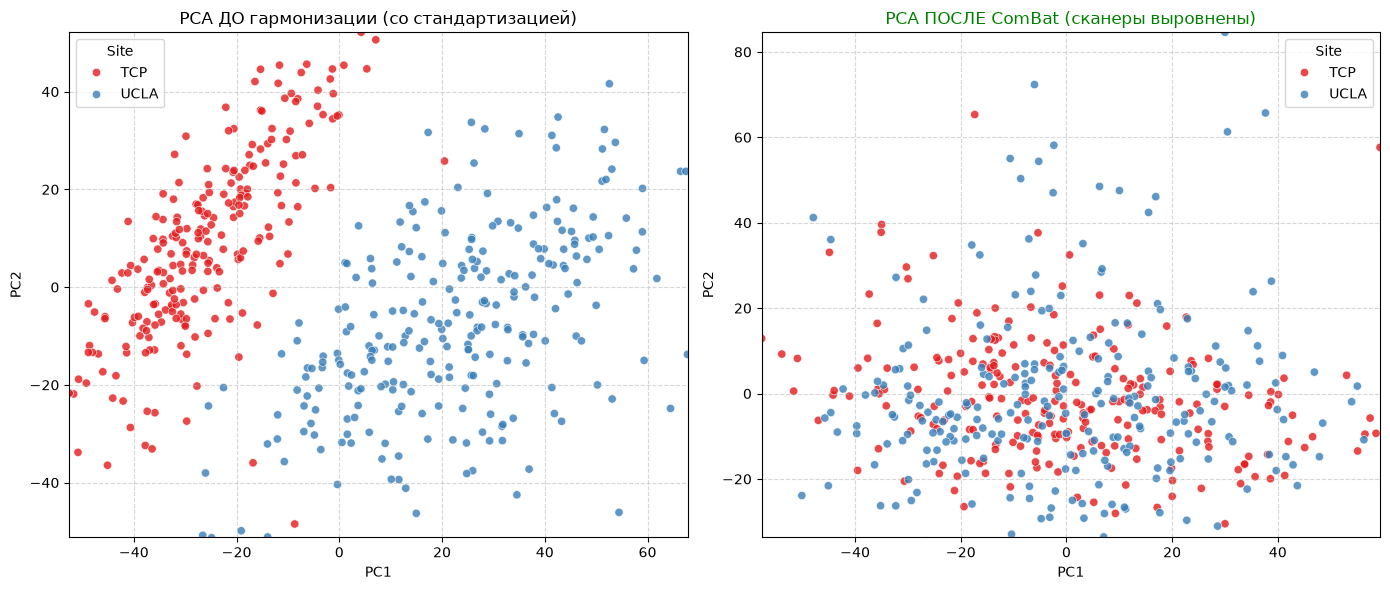

📊 Новый честный график PCA сохранен в: /media/melting/5A80-1912/student_data/1_6/pca_combat_comparison.png


In [6]:
# ==========================================
# КОНФИГУРАЦИЯ И ПУТИ ПРОЕКТА
# ==========================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Проверяем наличие библиотеки neuroCombat
try:
    from neuroCombat import neuroCombat
except ImportError:
    !pip install neuroCombat
    from neuroCombat import neuroCombat

USB_ROOT = "/media/melting/5A80-1912/student_data"
DIR_1_3 = os.path.join(USB_ROOT, "1_3")
DIR_1_4 = os.path.join(USB_ROOT, "1_4")
DIR_1_5 = os.path.join(USB_ROOT, "1_5")
DIR_1_6 = os.path.join(USB_ROOT, "1_6") # Новая директория для этапа 1.6

os.makedirs(DIR_1_5, exist_ok=True)
os.makedirs(DIR_1_6, exist_ok=True)

NOSOLOGIES_FILE = os.path.join(DIR_1_3, "nosologies.json")
INPUT_MEASUREMENTS = os.path.join(DIR_1_4, "measurements_with_legend.npz")
IMPUTED_MATRIX = os.path.join(DIR_1_5, "mrt_matrix_knn_imputed.npz")

print("--- Этап 1.6: Межцентровая гармонизация данных (ComBat) ---")
print(f"📁 Все результаты сохраняются в папку: {DIR_1_6}")

# 1. Загружаем заполненную/импутированную матрицу для ML
data_load = np.load(IMPUTED_MATRIX, allow_pickle=True)
X = data_load["data"]
cols = data_load["cols"]
rows = data_load["rows"]
X_df = pd.DataFrame(X, columns=cols, index=rows)

# 2. Загружаем nosologies.json для получения информации о сканере (site), возрасте и диагнозе
with open(NOSOLOGIES_FILE, 'r', encoding='utf-8') as f:
    nosologies_data = json.load(f)

# Собираем DataFrame с ковариатами для каждого пациента в том же порядке, что и строки X_df
covars_list = []
for pid in rows:
    p_info = nosologies_data.get(pid, {})
    covars_list.append({
        'patient_id': pid,
        'site': p_info.get('dataset', 'UCLA'), # UCLA или TCP
        'age': p_info.get('age', 30),
        'gender': p_info.get('gender', 'M'),
        'disease': p_info.get('nosology', 'CONTROL')
    })

df_covars = pd.DataFrame(covars_list)

# 3. Подготовка данных для neuroCombat
# neuroCombat ожидает матрицу: признаки (строки) x пациенты (столбцы)
dat_for_combat = X_df.T.values

# Формируем единый DataFrame ковариатов, включая колонку батча ('site') и биологические факторы
design_df = pd.DataFrame({
    'site': df_covars['site'].values, # Колонка сканера/батча
    'age': pd.to_numeric(df_covars['age'], errors='coerce').fillna(30),
    'is_schz': (df_covars['disease'] == 'SCHZ').astype(int),
    'is_bap': (df_covars['disease'] == 'BAP').astype(int) if 'BAP' in df_covars['disease'].values else 0
})

print("🔄 Запуск алгоритма ComBat для устранения эффекта сканера...")
combat_results = neuroCombat(
    dat=dat_for_combat,
    covars=design_df,
    batch_col='site',
    categorical_cols=['is_schz'],
    continuous_cols=['age']
)

# Извлекаем гармонизированную матрицу и возвращаем к форме: пациенты x признаки
X_harmonized = combat_results['data'].T
X_harm_df = pd.DataFrame(X_harmonized, columns=cols, index=rows)

# Сохраняем гармонизированные данные в NPZ внутри папки 1_6
harmonized_npz_path = os.path.join(DIR_1_6, "harmonized_imputed_matrix.npz")
np.savez(harmonized_npz_path, data=X_harmonized, cols=cols, rows=rows)
print(f"✅ Гармонизированная матрица сохранена в: {harmonized_npz_path}")

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("--- Построение честного PCA с предварительной стандартизацией ---")

# 1. Обязательно стандартизируем данные (выравниваем масштаб всех 1000+ признаков)
scaler = StandardScaler()
X_raw_scaled = scaler.fit_transform(X_df.fillna(0))
X_harm_scaled = scaler.fit_transform(X_harm_df.fillna(0))

# 2. Запускаем PCA
pca = PCA(n_components=2)

# До ComBat
X_pca_raw = pca.fit_transform(X_raw_scaled)
df_plot_raw = pd.DataFrame(X_pca_raw, columns=['PC1', 'PC2'])
df_plot_raw['Site'] = df_covars['site'].values

# После ComBat
X_pca_harm = pca.fit_transform(X_harm_scaled)
df_plot_harm = pd.DataFrame(X_pca_harm, columns=['PC1', 'PC2'])
df_plot_harm['Site'] = df_covars['site'].values

# 3. Строим графики с ограничением экстремальных выбросов по осям для красивой визуализации
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График ДО
sns.scatterplot(data=df_plot_raw, x='PC1', y='PC2', hue='Site', palette='Set1', alpha=0.8, ax=axes[0])
axes[0].set_title("PCA ДО гармонизации (со стандартизацией)")
axes[0].grid(True, linestyle='--', alpha=0.5)
# Ограничиваем оси по 99-му перцентилю, чтобы одиночные аномалии не ломали масштаб сетки
axes[0].set_xlim(np.percentile(df_plot_raw['PC1'], [1, 99]))
axes[0].set_ylim(np.percentile(df_plot_raw['PC2'], [1, 99]))

# График ПОСЛЕ
sns.scatterplot(data=df_plot_harm, x='PC1', y='PC2', hue='Site', palette='Set1', alpha=0.8, ax=axes[1])
axes[1].set_title("PCA ПОСЛЕ ComBat (сканеры выровнены)", color='green')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xlim(np.percentile(df_plot_harm['PC1'], [1, 99]))
axes[1].set_ylim(np.percentile(df_plot_harm['PC2'], [1, 99]))

plt.tight_layout()
pca_plot_path = os.path.join(DIR_1_6, "pca_combat_comparison.png")
plt.savefig(pca_plot_path, dpi=300)
plt.show()

print(f"📊 Новый честный график PCA сохранен в: {pca_plot_path}")

--- Построение PCA-кластеров в разрезе нозологий (после ComBat) ---


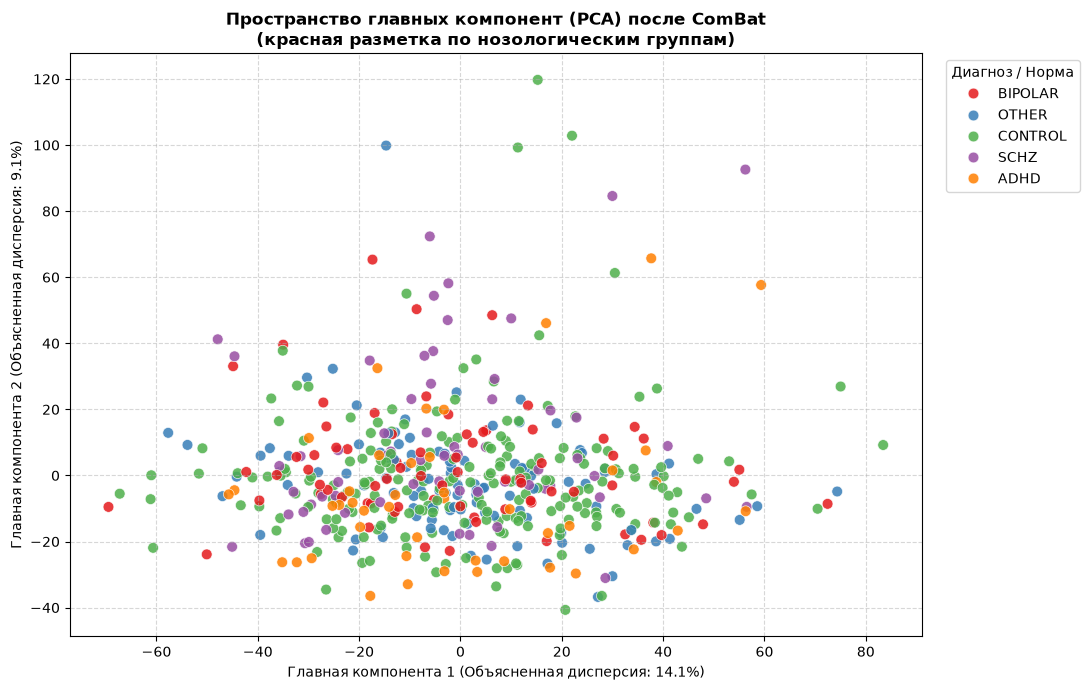

✅ График распределения нозологий успешно сохранен в: /media/melting/5A80-1912/student_data/1_6/pca_nosology_clusters.png


In [7]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ КЛАСТЕРОВ НОЗОЛОГИЙ (Этап 3.2)
# ==========================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

USB_ROOT = "/media/melting/5A80-1912/student_data"
DIR_1_3 = os.path.join(USB_ROOT, "1_3")
DIR_1_6 = os.path.join(USB_ROOT, "1_6")

NOSOLOGIES_FILE = os.path.join(DIR_1_3, "nosologies.json")
HARMONIZED_MATRIX = os.path.join(DIR_1_6, "harmonized_imputed_matrix.npz")

print("--- Построение PCA-кластеров в разрезе нозологий (после ComBat) ---")

# 1. Загружаем гармонизированную матрицу
data_load = np.load(HARMONIZED_MATRIX, allow_pickle=True)
X_harm = data_load["data"]
cols = data_load["cols"]
rows = data_load["rows"]
X_harm_df = pd.DataFrame(X_harm, columns=cols, index=rows)

# 2. Загружаем метаданные (диагнозы пациентов)
with open(NOSOLOGIES_FILE, 'r', encoding='utf-8') as f:
    nosologies_data = json.load(f)

diseases = []
for pid in rows:
    p_info = nosologies_data.get(pid, {})
    diseases.append(p_info.get('nosology', 'CONTROL'))

df_plot = pd.DataFrame({'disease': diseases}, index=rows)

# 3. Стандартизация гармонизированных данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_harm_df.fillna(0))

# 4. Запускаем PCA с сохранением главных компонент
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_plot['PC1'] = X_pca[:, 0]
df_plot['PC2'] = X_pca[:, 1]

# 5. Строим scatter-plot с цветовой разметкой по заболеваниям
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_plot, 
    x='PC1', y='PC2', 
    hue='disease', 
    palette='Set1', 
    alpha=0.85, 
    s=60,
    edgecolor='w',
    linewidth=0.5
)

# Оформление графика
expl_var = pca.explained_variance_ratio_ * 100
plt.title("Пространство главных компонент (PCA) после ComBat\n(красная разметка по нозологическим группам)", fontsize=12, fontweight='bold')
plt.xlabel(f"Главная компонента 1 (Объясненная дисперсия: {expl_var[0]:.1f}%)", fontsize=10)
plt.ylabel(f"Главная компонента 2 (Объясненная дисперсия: {expl_var[1]:.1f}%)", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Выносим легенду за пределы графика для аккуратности
plt.legend(title="Диагноз / Норма", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()

# Сохраняем результат в папку 1_6
output_plot_path = os.path.join(DIR_1_6, "pca_nosology_clusters.png")
plt.savefig(output_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ График распределения нозологий успешно сохранен в: {output_plot_path}")

--- Анализ альтернативных признаков в пространстве PCA ---


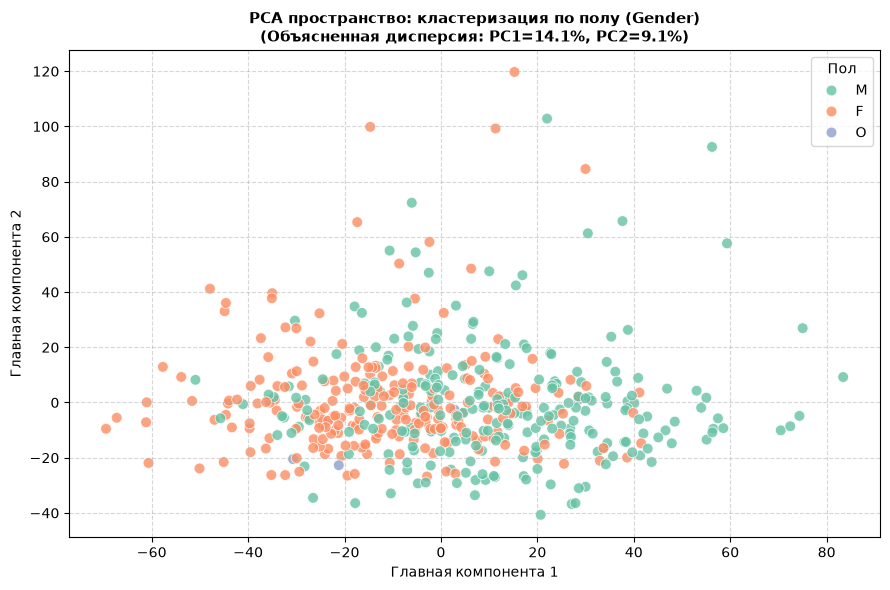

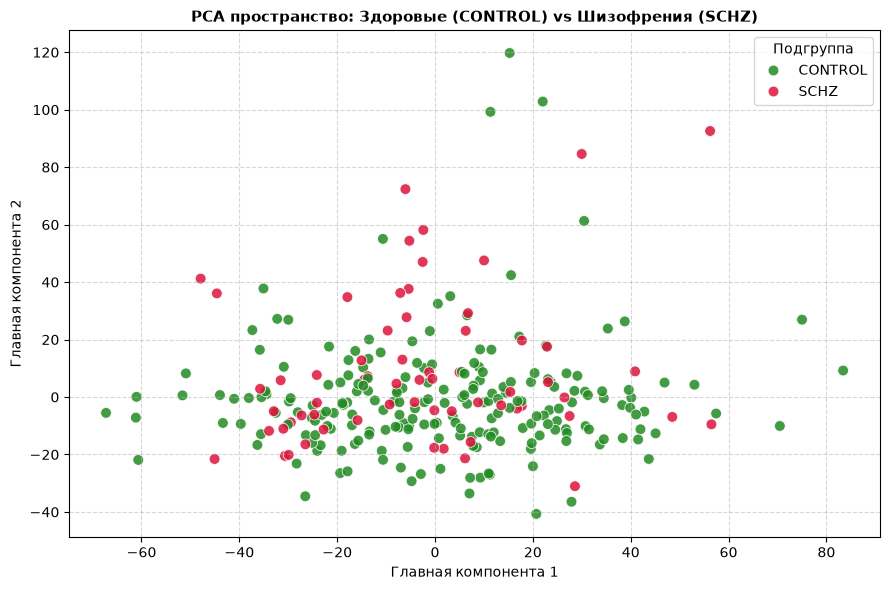

✅ Дополнительные графики по полу и попарному сравнению сохранены в папку: /media/melting/5A80-1912/student_data/1_6


In [8]:
# ==========================================
# АЛЬТЕРНАТИВНАЯ КЛАСТЕРИЗАЦИЯ: ПОЛ И КОНТРОЛЬ vs ШИЗОФРЕНИЯ
# ==========================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

USB_ROOT = "/media/melting/5A80-1912/student_data"
DIR_1_3 = os.path.join(USB_ROOT, "1_3")
DIR_1_6 = os.path.join(USB_ROOT, "1_6")

NOSOLOGIES_FILE = os.path.join(DIR_1_3, "nosologies.json")
HARMONIZED_MATRIX = os.path.join(DIR_1_6, "harmonized_imputed_matrix.npz")

print("--- Анализ альтернативных признаков в пространстве PCA ---")

# 1. Загружаем данные и метаданные
data_load = np.load(HARMONIZED_MATRIX, allow_pickle=True)
X_harm = data_load["data"]
cols = data_load["cols"]
rows = data_load["rows"]
X_harm_df = pd.DataFrame(X_harm, columns=cols, index=rows)

with open(NOSOLOGIES_FILE, 'r', encoding='utf-8') as f:
    nosologies_data = json.load(f)

genders = []
diseases = []
for pid in rows:
    p_info = nosologies_data.get(pid, {})
    genders.append(p_info.get('gender', 'M'))
    diseases.append(p_info.get('nosology', 'CONTROL'))

df_meta = pd.DataFrame({'gender': genders, 'disease': diseases}, index=rows)

# 2. Стандартизация и PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_harm_df.fillna(0))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_meta['PC1'] = X_pca[:, 0]
df_meta['PC2'] = X_pca[:, 1]

expl_var = pca.explained_variance_ratio_ * 100

# 3. График 1: Разметка по полу (Gender) — обычно здесь виден сильный биологический сигнал
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_meta, x='PC1', y='PC2', hue='gender', palette='Set2', alpha=0.8, s=60
)
plt.title(f"PCA пространство: кластеризация по полу (Gender)\n(Объясненная дисперсия: PC1={expl_var[0]:.1f}%, PC2={expl_var[1]:.1f}%)", fontsize=11, fontweight='bold')
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Пол", loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(DIR_1_6, "pca_gender_clusters.png"), dpi=300)
plt.show()

# 4. График 2: Попарное сравнение строго CONTROL vs SCHZ (как требует этап биостатистики)
df_binary = df_meta[df_meta['disease'].isin(['CONTROL', 'SCHZ'])]

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_binary, x='PC1', y='PC2', hue='disease', palette={'CONTROL': 'forestgreen', 'SCHZ': 'crimson'}, alpha=0.85, s=60
)
plt.title("PCA пространство: Здоровые (CONTROL) vs Шизофрения (SCHZ)", fontsize=11, fontweight='bold')
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Подгруппа", loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(DIR_1_6, "pca_control_vs_schz.png"), dpi=300)
plt.show()

print(f"✅ Дополнительные графики по полу и попарному сравнению сохранены в папку: {DIR_1_6}")

--- Запуск алгоритма t-SNE поверх PCA-базиса ---
📉 Данные сжаты с 4545 признаков до 30 главных компонент PCA.
🔄 Вычисление t-SNE проекции...


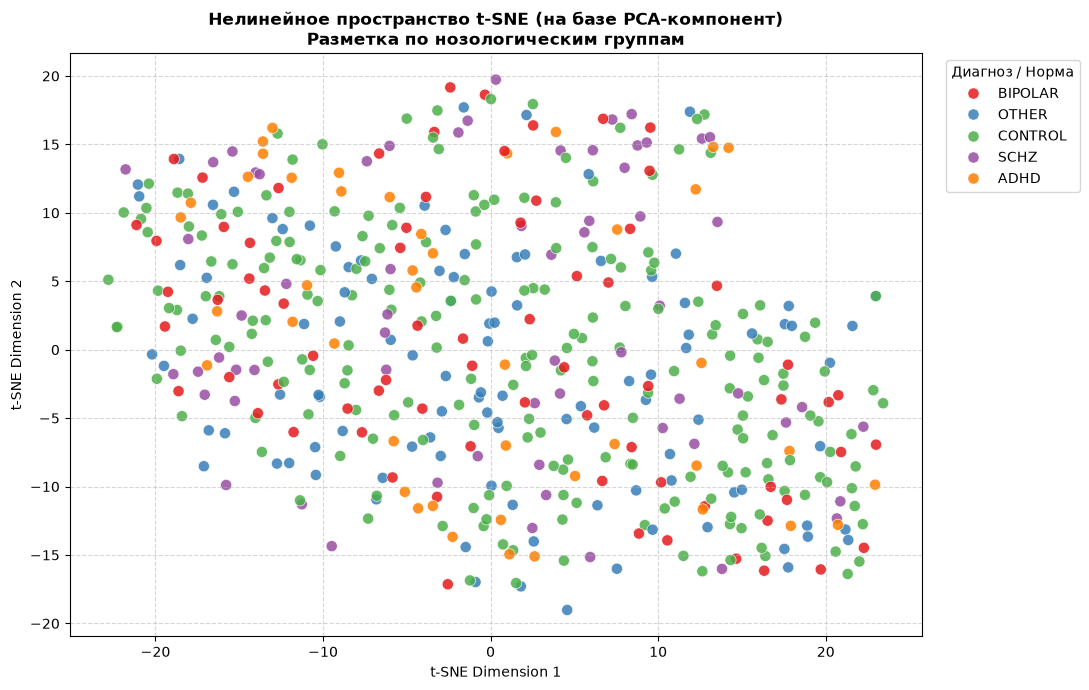

✅ График t-SNE успешно сохранен в папку: /media/melting/5A80-1912/student_data/3_0


In [10]:
# ==========================================
# ЭТАП 3.2: НЕЛИНЕЙНАЯ ВИЗУАЛИЗАЦИЯ t-SNE (поверх PCA)
# ==========================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Пути и директории
USB_ROOT = "/media/melting/5A80-1912/student_data"
DIR_1_3 = os.path.join(USB_ROOT, "1_3")
DIR_1_6 = os.path.join(USB_ROOT, "1_6")
DIR_3_0 = os.path.join(USB_ROOT, "3_0") # Новая директория для Этапа 3
os.makedirs(DIR_3_0, exist_ok=True)

NOSOLOGIES_FILE = os.path.join(DIR_1_3, "nosologies.json")
HARMONIZED_MATRIX = os.path.join(DIR_1_6, "harmonized_imputed_matrix.npz")

print("--- Запуск алгоритма t-SNE поверх PCA-базиса ---")

# 1. Загружаем гармонизированные данные
data_load = np.load(HARMONIZED_MATRIX, allow_pickle=True)
X_harm = data_load["data"]
cols = data_load["cols"]
rows = data_load["rows"]
X_harm_df = pd.DataFrame(X_harm, columns=cols, index=rows)

# 2. Загружаем диагнозы пациентов
with open(NOSOLOGIES_FILE, 'r', encoding='utf-8') as f:
    nosologies_data = json.load(f)

diseases = []
for pid in rows:
    p_info = nosologies_data.get(pid, {})
    diseases.append(p_info.get('nosology', 'CONTROL'))

df_tsne = pd.DataFrame({'disease': diseases}, index=rows)

# 3. Стандартизация и сжатие через PCA (берем первые 30 компонент, объясняющие большую часть дисперсии)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_harm_df.fillna(0))

pca = PCA(n_components=30, random_state=42)
X_pca_latent = pca.fit_transform(X_scaled)
print(f"📉 Данные сжаты с {X_scaled.shape[1]} признаков до 30 главных компонент PCA.")

# 4. Применяем t-SNE строго на матрицу PCA (согласно инструкции Этапа 3.2.б)
print("🔄 Вычисление t-SNE проекции...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_pca_latent)

df_tsne['tSNE_1'] = X_tsne[:, 0]
df_tsne['tSNE_2'] = X_tsne[:, 1]

# 5. Визуализация результатов t-SNE
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_tsne,
    x='tSNE_1', y='tSNE_2',
    hue='disease',
    palette='Set1',
    alpha=0.85,
    s=65,
    edgecolor='w',
    linewidth=0.5
)

plt.title("Нелинейное пространство t-SNE (на базе PCA-компонент)\nРазметка по нозологическим группам", fontsize=12, fontweight='bold')
plt.xlabel("t-SNE Dimension 1", fontsize=10)
plt.ylabel("t-SNE Dimension 2", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title="Диагноз / Норма", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()

tsne_plot_path = os.path.join(DIR_3_0, "tsne_nosology_clusters.png")
plt.savefig(tsne_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ График t-SNE успешно сохранен в папку: {DIR_3_0}")